# 泰勒展开（Taylor Expansion）在商业与运营决策中的量化应用

在复杂且非线性的商业世界中，管理者常面临**“预算调优”**与**“收益预测”**的难题。常见的决策误区在于**盲目使用“线性思维”**（例如：以为多花 50% 的营销预算就能多带来 50% 的新客）。

本 Notebook 展示了如何利用**泰勒展开式**将高等数学原语转化为商业决策模型：

---

### 一、 核心数学原语与商业语言映射

泰勒展开式的本质是：**利用当前已知点（基线）的各阶导数，去精准预测未来变化点的非线性走势。**

$$
\begin{aligned}
f(x_0 + \Delta x) &\approx \underbrace{f(x_0)}_{\text{零阶项 (基线)}} + \underbrace{f'(x_0) \cdot \Delta x}_{\text{一阶项 (切线/边际速度)}} + \underbrace{\frac{1}{2!} f''(x_0) \cdot (\Delta x)^2}_{\text{二阶项 (曲率/饱和加速度)}} + \mathcal{O}((\Delta x)^3)
\end{aligned}
$$

1. **零阶项 $f(x_0)$ —— 现状基本盘**
   - **商业含义**：当前业务的基线收益（如现有投入下的月新增用户数/营收）。
2. **一阶导数 $f'(x_0)$ —— 当下边际速率（速度）**
   - **商业含义**：当下的边际 ROI（每多投入 1 单位预算，当前能带来多少单位收益）。
   - **决策误区**：仅靠 $f'(x_0)$ 线性外推，会忽略市场饱和风险，导致预测**过分乐观**。
3. **二阶导数 $f''(x_0)$ —— 衰减加速度与曲率（弯曲度）**
   - **商业含义**：渠道饱和与边际递减效应。
   - **$f''(x_0) < 0$**：警示存在“边际递减”，模型会自动扣减收益预期，帮助管理者踩刹车。
   - **$f''(x_0) = 0$**：代表完美的线性增长，说明业务正处于强劲红利期，可继续追加投入。

---

### 二、 决策分析流（Workflow）

1. **数据拟合**：基于历史投入与收益数据，通过最小二乘法拟合出业务收益曲线 $f(x)$。
2. **状态诊断**：计算当前基准点 $x_0$ 处的一阶导数 $f'(x_0)$ 和二阶导数 $f''(x_0)$。
3. **泰勒预测对比**：对比**一阶线性预测**与**二阶泰勒修正预测**的差异，算出“渠道饱和损耗”。
4. **可视化归因**：绘制收益曲线、切线及抛物线修正图，导出最终高管汇报结论。


<>:71: SyntaxWarning: invalid escape sequence '\l'
<>:71: SyntaxWarning: invalid escape sequence '\l'
C:\Users\quzhe\AppData\Local\Temp\ipykernel_20484\1354032895.py:71: SyntaxWarning: invalid escape sequence '\l'
  ax.plot(x_curve, log_model(x_curve, A_fit), 'b-', linewidth=2.5, label=f'收益曲线 $f(x) = {A_fit:.0f} \ln(x+1)$')


【模型拟合结果】拟合函数: f(x) = 502.18 * ln(x + 1), R² = 0.9992
基准点 x0 = 100.0 万元 时:
  └─ 零阶项 f(x0)     = 2317.64 人 (当前基本盘)
  └─ 一阶导数 f'(x0)   = 4.9721 人/万元 (边际速率)
  └─ 二阶导数 f''(x0)  = -0.049229 人/万元² (饱和加速度)

当预算增加 Δx = 50.0 万元 (投入至 150.0 万元) 时:
  ├─ 1. 真实目标新客数          : 2519.60 人
  ├─ 2. 一阶盲目乐观预测(线性)   : 2566.24 人 (偏差: +46.65 人)
  └─ 3. 二阶泰勒精准预测(含修正) : 2504.71 人 (偏差: -14.89 人)


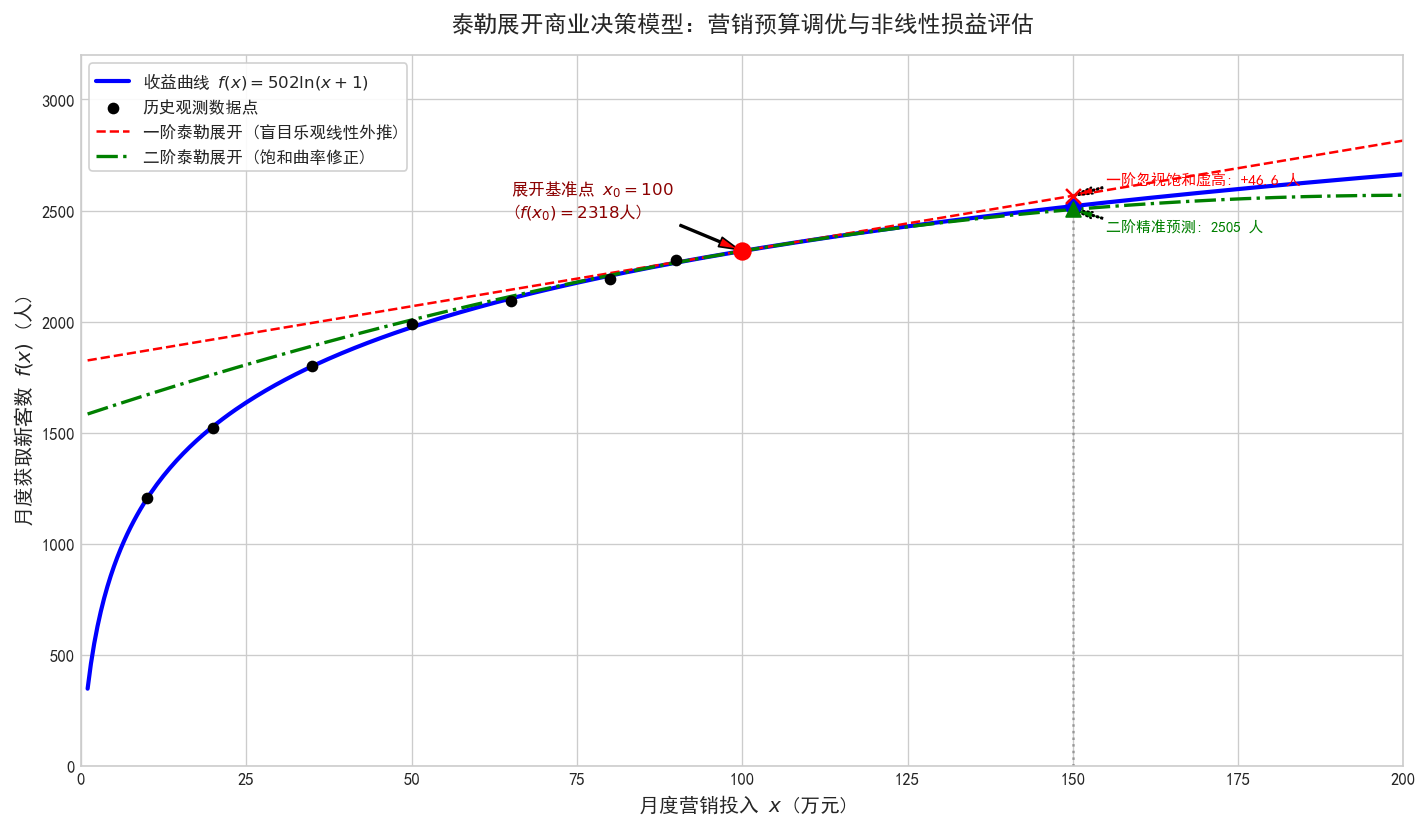

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score

# 1. 绘图环境设置
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ==========================================
# 2. 模拟历史业务数据与拟合
# ==========================================
# 模拟 12 个月的历史营销投入 x (万元) 与 对应的产出 y (新客数)
np.random.seed(42)
x_history = np.array([10, 20, 35, 50, 65, 80, 90, 100])
y_history = 500 * np.log(x_history + 1) + \
    np.random.normal(0, 15, size=len(x_history))

# 定义非线性收益函数模板 (对数模型: 刻画边际递减)


def log_model(x, A):
    return A * np.log(x + 1)


# 最小二乘拟合求解系数 A
popt, _ = curve_fit(log_model, x_history, y_history)
A_fit = popt[0]

# 评估拟合优度 R²
y_pred_hist = log_model(x_history, A_fit)
r2 = r2_score(y_history, y_pred_hist)

print("="*50)
print(f"【模型拟合结果】拟合函数: f(x) = {A_fit:.2f} * ln(x + 1), R² = {r2:.4f}")
print("="*50)

# ==========================================
# 3. 泰勒展开导数推导 (基准点 x0 = 100 万元)
# ==========================================
x0 = 100.0        # 当前投入基线
x_target = 150.0  # 计划调整的目标投入 (增加 50 万元)
dx = x_target - x0

# 解析求导
f_x0 = A_fit * np.log(x0 + 1)         # 零阶项
df_x0 = A_fit / (x0 + 1)              # 一阶导数 f'(x0)
d2f_x0 = -A_fit / ((x0 + 1) ** 2)     # 二阶导数 f''(x0)

# 泰勒各阶项数值计算
y_linear = f_x0 + df_x0 * dx                              # 一阶预测 (线性外推)
y_taylor2 = f_x0 + df_x0 * dx + 0.5 * d2f_x0 * (dx ** 2)  # 二阶预测 (曲率修正)
y_true = log_model(x_target, A_fit)                       # 真实函数值

print(f"基准点 x0 = {x0} 万元 时:")
print(f"  └─ 零阶项 f(x0)     = {f_x0:.2f} 人 (当前基本盘)")
print(f"  └─ 一阶导数 f'(x0)   = {df_x0:.4f} 人/万元 (边际速率)")
print(f"  └─ 二阶导数 f''(x0)  = {d2f_x0:.6f} 人/万元² (饱和加速度)\n")

print(f"当预算增加 Δx = {dx} 万元 (投入至 {x_target} 万元) 时:")
print(f"  ├─ 1. 真实目标新客数          : {y_true:.2f} 人")
print(
    f"  ├─ 2. 一阶盲目乐观预测(线性)   : {y_linear:.2f} 人 (偏差: {y_linear - y_true:+.2f} 人)")
print(
    f"  └─ 3. 二阶泰勒精准预测(含修正) : {y_taylor2:.2f} 人 (偏差: {y_taylor2 - y_true:+.2f} 人)")
print("="*50)

# ==========================================
# 4. 图形可视化演示
# ==========================================
x_curve = np.linspace(1, 200, 400)

fig, ax = plt.subplots(figsize=(12, 7), dpi=120)

# 绘制拟合收益曲线与历史散点
ax.plot(x_curve, log_model(x_curve, A_fit), 'b-', linewidth=2.5,
        label=f'收益曲线 $f(x) = {A_fit:.0f} \ln(x+1)$')
ax.scatter(x_history, y_history, color='black', zorder=5, label='历史观测数据点')

# 绘制一阶切线与二阶修正抛物线
ax.plot(x_curve, f_x0 + df_x0 * (x_curve - x0), 'r--',
        linewidth=1.5, label='一阶泰勒展开 (盲目乐观线性外推)')
ax.plot(x_curve, f_x0 + df_x0 * (x_curve - x0) + 0.5 * d2f_x0 *
        ((x_curve - x0)**2), 'g-.', linewidth=2, label='二阶泰勒展开 (饱和曲率修正)')

# 标注基准点 x0
ax.scatter([x0], [f_x0], color='red', s=100, zorder=6)
ax.annotate(f'展开基准点 $x_0={x0:.0f}$\n($f(x_0)={f_x0:.0f}$人)',
            xy=(x0, f_x0), xytext=(x0 - 35, f_x0 + 150),
            arrowprops=dict(facecolor='red', shrink=0.05,
                            width=1, headwidth=6),
            fontsize=10, fontweight='bold', color='darkred')

# 标注预测目标点 x = 150
ax.vlines(x_target, ymin=0, ymax=y_linear,
          colors='gray', linestyles=':', alpha=0.7)
ax.scatter([x_target], [y_true], color='blue', s=80, zorder=6)
ax.scatter([x_target], [y_linear], color='red', marker='x', s=80, zorder=6)
ax.scatter([x_target], [y_taylor2], color='green', marker='^', s=80, zorder=6)

# 标注误差说明
ax.annotate(f'一阶忽视饱和虚高: {y_linear - y_true:+.1f} 人',
            xy=(x_target, y_linear), xytext=(x_target + 5, y_linear + 50),
            arrowprops=dict(facecolor='red', linestyle=':',
                            width=0.8, headwidth=4),
            fontsize=9, color='red')

ax.annotate(f'二阶精准预测: {y_taylor2:.0f} 人',
            xy=(x_target, y_taylor2), xytext=(x_target + 5, y_taylor2 - 100),
            arrowprops=dict(facecolor='green', linestyle=':',
                            width=0.8, headwidth=4),
            fontsize=9, color='green')

# 细节样式调整
ax.set_title('泰勒展开商业决策模型：营销预算调优与非线性损益评估',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('月度营销投入 $x$ (万元)', fontsize=12)
ax.set_ylabel('月度获取新客数 $f(x)$ (人)', fontsize=12)
ax.set_xlim(0, 200)
ax.set_ylim(0, 3200)
ax.legend(loc='upper left', frameon=True,
          facecolor='white', framealpha=0.9, fontsize=10)

plt.tight_layout()
plt.show()